# Classifying Pet Photos with Deep Learning: Dogs vs. Cats

**Predictive Analytics (MSBA 6421) · Carlson School of Management, University of Minnesota** · Author: Parul Chaudhary
Kaggle competition: [Dogs vs. Cats Redux: Kernels Edition](https://www.kaggle.com/competitions/dogs-vs-cats-redux-kernels-edition) · run on Kaggle (2× Tesla T4 GPUs)

| Model | Best validation accuracy | Kaggle log loss (lower = better) |
|---|---|---|
| CNN from scratch (baseline) | 77.1% | — |
| ResNet50, transfer learning + fine-tuning (predictions clipped) | ~98% | 0.05453 |
| EfficientNetB4, transfer learning + fine-tuning (no clipping) | 99.1% | 0.06584 |
| EfficientNetB4, transfer learning + fine-tuning (predictions clipped to [0.01, 0.99]) | 99.1% | **0.04553** |

> **Note on reconstructed cells.** The model-definition cells for EfficientNetB4 were missing from the saved notebook. Cells marked **🔧 Reconstructed** or **🔧 Edited** were rebuilt from the architecture documented in the project report (`report/Pet_Image_Classifier_Report.pdf`) so the notebook reads end to end. All training outputs shown are from the original Kaggle run.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print(f'TensorFlow version: {tf.__version__}')


TensorFlow version: 2.19.0


In [2]:
import zipfile

# Unzip train and test files
with zipfile.ZipFile('/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/train.zip', 'r') as z:
    z.extractall('/kaggle/working/')

with zipfile.ZipFile('/kaggle/input/competitions/dogs-vs-cats-redux-kernels-edition/test.zip', 'r') as z:
    z.extractall('/kaggle/working/')

print('Train images:', len(os.listdir('/kaggle/working/train')))
print('Test images :', len(os.listdir('/kaggle/working/test')))

Train images: 25000
Test images : 12500


In [3]:
# Organise train images into cats and dogs subfolders
# ImageDataGenerator requires images to be in separate folders per class
import shutil

base_dir = '/kaggle/working/data'
train_dir = os.path.join(base_dir, 'train')
cat_dir   = os.path.join(train_dir, 'cats')
dog_dir   = os.path.join(train_dir, 'dogs')

# Create folders
os.makedirs(cat_dir, exist_ok=True)
os.makedirs(dog_dir, exist_ok=True)

# Copy images to respective folders based on filename
for filename in os.listdir('/kaggle/working/train'):
    if 'cat' in filename:
        shutil.copy(os.path.join('/kaggle/working/train', filename), os.path.join(cat_dir, filename))
    else:
        shutil.copy(os.path.join('/kaggle/working/train', filename), os.path.join(dog_dir, filename))

print(f'Cats : {len(os.listdir(cat_dir))}')
print(f'Dogs : {len(os.listdir(dog_dir))}')

Cats : 12500
Dogs : 12500


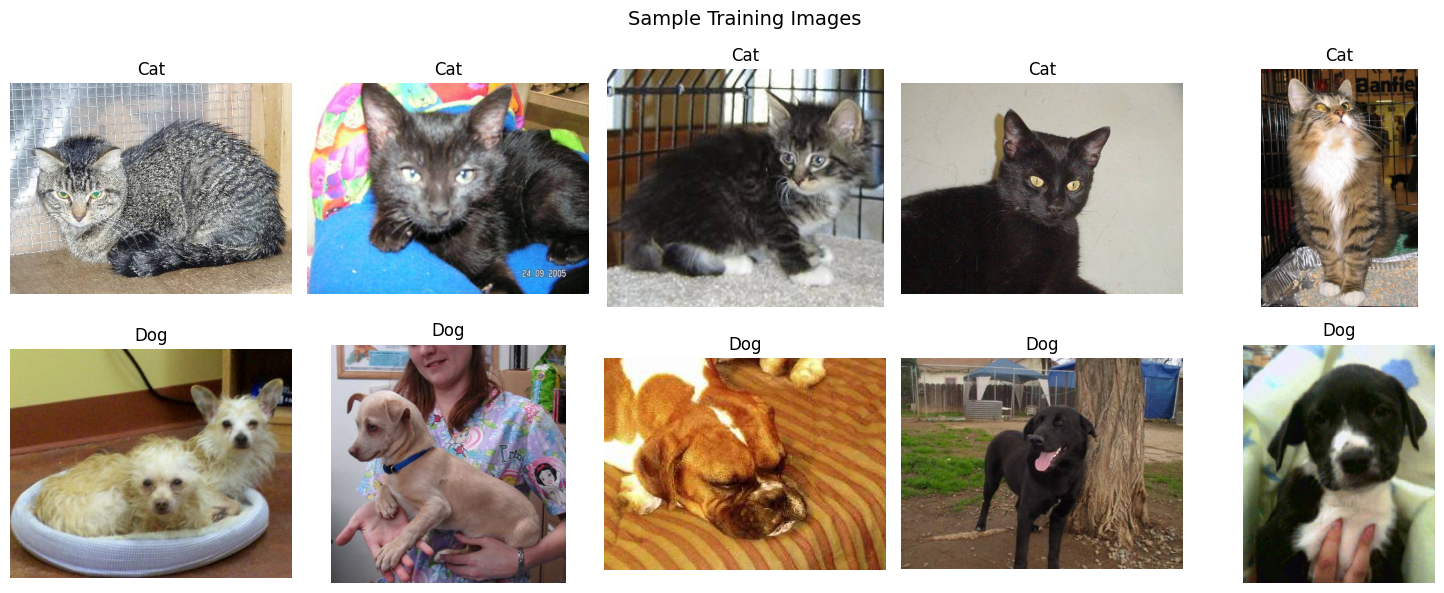

In [14]:
from PIL import Image
import matplotlib.pyplot as plt

# Visualise sample cats and dogs from training set
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Sample Training Images', fontsize=14)

# Get 5 cat images
cat_images = os.listdir(cat_dir)[:5]
dog_images = os.listdir(dog_dir)[:5]

# Plot cats in first row
for i, img_name in enumerate(cat_images):
    img = Image.open(os.path.join(cat_dir, img_name))
    axes[0, i].imshow(img)
    axes[0, i].set_title('Cat')
    axes[0, i].axis('off')

# Plot dogs in second row
for i, img_name in enumerate(dog_images):
    img = Image.open(os.path.join(dog_dir, img_name))
    axes[1, i].imshow(img)
    axes[1, i].set_title('Dog')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


In [4]:
# Set up ImageDataGenerator with augmentation for training and validation
img_size   = 224
batch_size = 32

# Training data generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,              # normalize pixel values to [0,1]
    validation_split=0.2,        # 20% for validation
    horizontal_flip=True,        # randomly flip horizontally
    vertical_flip=True,          # randomly flip vertically
    rotation_range=20,           # randomly rotate up to 20 degrees
    zoom_range=0.2,              # randomly zoom in/out
    brightness_range=[0.8, 1.2]  # randomly change brightness
)

# Training generator
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary',
    subset='training'
)

# Validation generator — no augmentation
val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

print(f'Training images   : {train_generator.samples}')
print(f'Validation images : {val_generator.samples}')
print(f'Classes           : {train_generator.class_indices}')

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.
Training images   : 20000
Validation images : 5000
Classes           : {'cats': 0, 'dogs': 1}


In [5]:
# Model 1 — Simple CNN from scratch
# We start with a basic CNN to establish a baseline before using transfer learning

cnn_model = models.Sequential([
    # First conv block
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D(2, 2),

    # Second conv block
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Third conv block
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Fully connected layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),              # dropout to prevent overfitting
    layers.Dense(1, activation='sigmoid')  # binary output
])

# Compile with binary crossentropy loss
cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train CNN model — establishes baseline performance
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_cnn = cnn_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=6,
    callbacks=[early_stop]
)

# Print best results
print(f'Best Val Accuracy : {max(history_cnn.history["val_accuracy"]):.4f}')
print(f'Best Val Loss     : {min(history_cnn.history["val_loss"]):.4f}')

Epoch 1/6


  2/625 ━━━━━━━━━━━━━━━━━━━━ 35s 57ms/step - accuracy: 0.5703 - loss: 0.7572  

625/625 ━━━━━━━━━━━━━━━━━━━━ 317s 494ms/step - accuracy: 0.5300 - loss: 0.7137 - val_accuracy: 0.6160 - val_loss: 0.6526
Epoch 2/6
625/625 ━━━━━━━━━━━━━━━━━━━━ 309s 494ms/step - accuracy: 0.6219 - loss: 0.6541 - val_accuracy: 0.6630 - val_loss: 0.6115
Epoch 3/6
625/625 ━━━━━━━━━━━━━━━━━━━━ 302s 483ms/step - accuracy: 0.6585 - loss: 0.6230 - val_accuracy: 0.7180 - val_loss: 0.5501
Epoch 4/6
625/625 ━━━━━━━━━━━━━━━━━━━━ 299s 479ms/step - accuracy: 0.7046 - loss: 0.5728 - val_accuracy: 0.7506 - val_loss: 0.5108
Epoch 5/6
625/625 ━━━━━━━━━━━━━━━━━━━━ 301s 482ms/step - accuracy: 0.7385 - loss: 0.5240 - val_accuracy: 0.7712 - val_loss: 0.4889
Epoch 6/6
625/625 ━━━━━━━━━━━━━━━━━━━━ 304s 486ms/step - accuracy: 0.7679 - loss: 0.4914 - val_accuracy: 0.7702 - val_loss: 0.4852
Best Val Accuracy : 0.7712
Best Val Loss     : 0.4852


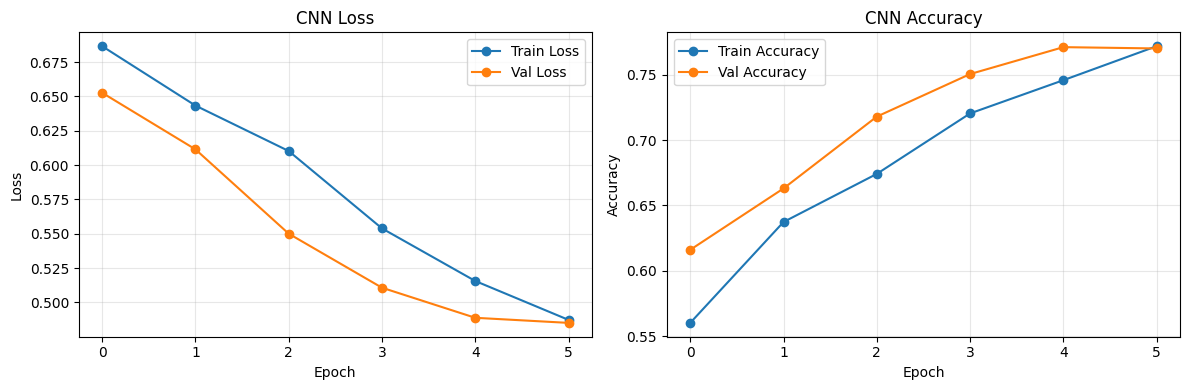

Best CNN Val Accuracy : 0.7712
Best CNN Val Loss     : 0.4852


In [7]:
# Plot CNN training results
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_cnn.history['loss'],     label='Train Loss', marker='o')
axes[0].plot(history_cnn.history['val_loss'], label='Val Loss',   marker='o')
axes[0].set_title('CNN Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_cnn.history['accuracy'],     label='Train Accuracy', marker='o')
axes[1].plot(history_cnn.history['val_accuracy'], label='Val Accuracy',   marker='o')
axes[1].set_title('CNN Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Best CNN Val Accuracy : {max(history_cnn.history["val_accuracy"]):.4f}')
print(f'Best CNN Val Loss     : {min(history_cnn.history["val_loss"]):.4f}')

### Model 2 — EfficientNetB4 (transfer learning)
🔧 **Reconstructed cell** — rebuilt from the architecture in the report: ImageNet-pretrained EfficientNetB4 with a frozen base, plus GlobalAveragePooling2D → BatchNormalization → Dense(512) → Dropout(0.5) → Dense(256) → Dropout(0.3) → sigmoid, trained at lr = 1e-3.

In [ ]:
# 🔧 Reconstructed — EfficientNetB4 data generators (model-specific ImageNet preprocessing + augmentation)
train_datagen_eff = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
)
train_generator_eff = train_datagen_eff.flow_from_directory(
    train_dir, target_size=(img_size, img_size), batch_size=batch_size,
    class_mode='binary', subset='training')
val_generator_eff = train_datagen_eff.flow_from_directory(
    train_dir, target_size=(img_size, img_size), batch_size=batch_size,
    class_mode='binary', subset='validation')

# 🔧 Reconstructed — pretrained EfficientNetB4 base (frozen) + custom classification head
base_model = EfficientNetB4(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3))
base_model.trainable = False

model_eff = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),
])
model_eff.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss='binary_crossentropy', metrics=['accuracy'])
model_eff.summary()

In [9]:
# Train EfficientNetB4 — first train only top layers
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_eff = model_eff.fit(
    train_generator_eff,
    validation_data=val_generator_eff,
    epochs=6,
    callbacks=[early_stop]
)

print(f'Best Val Accuracy : {max(history_eff.history["val_accuracy"]):.4f}')
print(f'Best Val Loss     : {min(history_eff.history["val_loss"]):.4f}')

Epoch 1/6


625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - accuracy: 0.9776 - loss: 0.0600

625/625 ━━━━━━━━━━━━━━━━━━━━ 349s 478ms/step - accuracy: 0.9776 - loss: 0.0599 - val_accuracy: 0.9898 - val_loss: 0.0271
Epoch 2/6
625/625 ━━━━━━━━━━━━━━━━━━━━ 273s 436ms/step - accuracy: 0.9911 - loss: 0.0263 - val_accuracy: 0.9910 - val_loss: 0.0284
Epoch 3/6
625/625 ━━━━━━━━━━━━━━━━━━━━ 268s 428ms/step - accuracy: 0.9919 - loss: 0.0218 - val_accuracy: 0.9898 - val_loss: 0.0324
Epoch 4/6
625/625 ━━━━━━━━━━━━━━━━━━━━ 267s 428ms/step - accuracy: 0.9940 - loss: 0.0182 - val_accuracy: 0.9908 - val_loss: 0.0291
Best Val Accuracy : 0.9910
Best Val Loss     : 0.0271


In [10]:
# Fine tune — unfreeze last 30 layers of EfficientNetB4
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with lower learning rate for fine tuning
model_eff.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_fine = model_eff.fit(
    train_generator_eff,
    validation_data=val_generator_eff,
    epochs=4,
    callbacks=[early_stop]
)

print(f'Best Val Accuracy : {max(history_fine.history["val_accuracy"]):.4f}')
print(f'Best Val Loss     : {min(history_fine.history["val_loss"]):.4f}')

Epoch 1/4
625/625 ━━━━━━━━━━━━━━━━━━━━ 327s 448ms/step - accuracy: 0.9741 - loss: 0.0819 - val_accuracy: 0.9868 - val_loss: 0.0371
Epoch 2/4
625/625 ━━━━━━━━━━━━━━━━━━━━ 264s 422ms/step - accuracy: 0.9832 - loss: 0.0472 - val_accuracy: 0.9892 - val_loss: 0.0322
Epoch 3/4
625/625 ━━━━━━━━━━━━━━━━━━━━ 266s 426ms/step - accuracy: 0.9859 - loss: 0.0403 - val_accuracy: 0.9886 - val_loss: 0.0307
Epoch 4/4
625/625 ━━━━━━━━━━━━━━━━━━━━ 270s 431ms/step - accuracy: 0.9878 - loss: 0.0340 - val_accuracy: 0.9914 - val_loss: 0.0282
Best Val Accuracy : 0.9914
Best Val Loss     : 0.0282


### Predictions & Kaggle submission
🔧 **Edited cell** — the saved notebook's prediction cell pointed to the ResNet50 model from a separate run. It now scores the test set with the fine-tuned EfficientNetB4 and **clips probabilities to [0.01, 0.99]** — the version that achieved the best Kaggle log loss (0.04553).

In [ ]:
# Generate predictions on the 12,500 test images with the fine-tuned EfficientNetB4
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

test_generator = test_datagen.flow_from_directory(
    '/kaggle/working/',
    classes=['test'],
    target_size=(img_size, img_size),
    batch_size=1,
    shuffle=False,
    class_mode=None
)

predictions = model_eff.predict(test_generator, verbose=1)

# Clip predictions to avoid extreme log-loss penalties on confident mistakes
predictions = np.clip(predictions, 0.01, 0.99)

print(f'Total predictions  : {len(predictions)}')
print(f'Sample predictions : {predictions[:5].flatten()}')

In [12]:
# Create submission file
filenames = test_generator.filenames
ids = [int(f.split('/')[1].split('.')[0]) for f in filenames]

submission = pd.DataFrame({
    'id':    ids,
    'label': predictions.flatten()
})

# Sort by id as required by Kaggle
submission = submission.sort_values('id').reset_index(drop=True)

submission.to_csv('/kaggle/working/submission.csv', index=False)
print('submission.csv saved!')
print(submission.head(10))

submission.csv saved!
   id  label
0   1   0.99
1   2   0.99
2   3   0.99
3   4   0.99
4   5   0.01
5   6   0.01
6   7   0.01
7   8   0.01
8   9   0.01
9  10   0.01


### Appendix — ResNet50 comparison model
This setup comes from an earlier version of the notebook. ResNet50 was trained and fine-tuned in a separate Kaggle run (≈98% validation accuracy; Kaggle log loss **0.05453**) — see the report for details.

In [ ]:
# Model 3 — ResNet50 with Transfer Learning (from an earlier notebook version; trained in a separate run)
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

train_datagen_res = ImageDataGenerator(
    preprocessing_function=resnet_preprocess,
    validation_split=0.2,
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.2
)
train_generator_res = train_datagen_res.flow_from_directory(
    train_dir, target_size=(224, 224), batch_size=32, class_mode='binary', subset='training')
val_generator_res = train_datagen_res.flow_from_directory(
    train_dir, target_size=(224, 224), batch_size=32, class_mode='binary', subset='validation')

base_model_res = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model_res.trainable = False

model_res = models.Sequential([
    base_model_res,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])
model_res.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss='binary_crossentropy', metrics=['accuracy'])